# 🚢 3D Container Loading Optimizer

## Project 10 — Introduction to AI (Spring 2025–2026)

**Aim:** Develop a logic-based logistics tool that computes the optimal packing of 3D boxes into a
standard shipping container to maximize volume utilization and stability, using **Genetic Algorithms**,
**Greedy Heuristics**, and **Simulated Annealing**.

---

### Problem Definition

Place a set of rectangular boxes $B = \{b_1, b_2, \ldots, b_n\}$ into a container $C$ such that:
- Every box fits **completely** inside the container boundaries
- **No two boxes overlap**
- Every box is **supported** by the floor or another box (gravity constraint)
- **Fragile** boxes cannot be flipped upside-down (orientation constraint)

### Objective Function

$$\text{Maximize Volume Utilization} = \frac{\sum \text{Vol}(b_i)}{\text{Vol}(C)} \times 100\%$$

Secondary objective: **Maximize Stability** — place heavy items at the bottom.

---

### Table of Contents

1. Setup & Imports
2. Data Models (Box, Container)
3. Data Loading & Exploration
4. Core Utility Functions
5. Space Manager — Placement Engine
6. Algorithm 1: Greedy Best-Fit Decreasing (BFD)
7. Algorithm 2: Genetic Algorithm (GA)
8. Algorithm 3: Simulated Annealing (SA)
9. Run All Algorithms
10. Comparative Evaluation
11. Solution Verification
12. 3D Visualization
13. Conclusion


## 1. Setup & Imports

We import standard Python libraries. All algorithm code is **self-contained** in this notebook — no external project modules are needed.


In [ ]:
import json
import os
import random
import math
import time
from collections import defaultdict

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
import numpy as np

%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100

print('All imports successful ✓')


All imports successful ✓


## 2. Data Models

We define two core data classes:
- **`Box`**: Represents a single box with dimensions (L×W×H), weight, and fragility attributes.
- **`Container`**: Represents the shipping container with inner dimensions (L×W×H).

These are used by all three algorithms.


In [ ]:
class Box:
    def __init__(self, id, l, w, h, weight=1, fragile=False, orientation_locked=False):
        self.id = id
        self.l = l
        self.w = w
        self.h = h
        self.weight = weight
        self.fragile = fragile
        self.orientation_locked = orientation_locked

    def volume(self):
        return self.l * self.w * self.h

    def __repr__(self):
        return f"Box(id={self.id}, {self.l}x{self.w}x{self.h}, weight={self.weight})"


class Container:
    def __init__(self, L, W, H):
        self.L = L
        self.W = W
        self.H = H

    def volume(self):
        return self.L * self.W * self.H

    def __repr__(self):
        return f"Container({self.L}x{self.W}x{self.H})"

print('Box and Container classes defined ✓')


Box and Container classes defined ✓


## 3. Data Loading & Exploration

### 3.1 Data Loader

The dataset is a JSON file containing:
- **Container**: ISO 20-foot Dry Freight Container (589 × 234 × 239 cm)
- **Box types**: 12 different box types with varying dimensions, weights, and quantities
- **Total boxes**: 386 individual box instances


In [ ]:
def load_data(path):
    with open(path) as f:
        data = json.load(f)
    c = data['container']['inner_dimensions']
    container = Container(c['length_cm'], c['width_cm'], c['height_cm'])
    boxes = []
    id_counter = 0
    for bt in data['box_types']:
        for _ in range(bt['quantity']):
            boxes.append(Box(
                id=id_counter, l=bt['length_cm'], w=bt['width_cm'], h=bt['height_cm'],
                weight=bt['weight_kg'], fragile=bt.get('fragile', False),
                orientation_locked=bt.get('orientation_locked', False),
            ))
            id_counter += 1
    return boxes, container


### 3.2 Load the Dataset


In [ ]:
DATA_PATH = os.path.join('..', 'data', 'project10_container_dataset.json')
boxes, container = load_data(DATA_PATH)
print(f'Container:  {container}')
print(f'Container volume: {container.volume():,} cm³')
print(f'Total boxes loaded: {len(boxes)}')
print(f'\nFirst 5 boxes:')
for b in boxes[:5]:
    print(f'  {b}  (vol={b.volume():,} cm³, fragile={b.fragile})')


Container:  Container(589x234x239)
Container volume: 32,940,414 cm³
Total boxes loaded: 386

First 5 boxes:
  Box(id=0, 80x60x70, weight=35.0)  (vol=336,000 cm³, fragile=False)
  Box(id=1, 80x60x70, weight=35.0)  (vol=336,000 cm³, fragile=False)
  Box(id=2, 80x60x70, weight=35.0)  (vol=336,000 cm³, fragile=False)
  Box(id=3, 80x60x70, weight=35.0)  (vol=336,000 cm³, fragile=False)
  Box(id=4, 80x60x70, weight=35.0)  (vol=336,000 cm³, fragile=False)


### 3.3 Dataset Exploration

Let's examine the dataset statistics and visualize the box type distribution.


In [ ]:
with open(DATA_PATH, encoding='utf-8') as f:
    raw_data = json.load(f)
print('=' * 90)
print(f"{'ID':<10} {'Label':<32} {'L×W×H (cm)':<16} {'Weight':<8} {'Qty':<5} {'Fragile':<8}")
print('=' * 90)
for bt in raw_data['box_types']:
    dims = f"{bt['length_cm']}×{bt['width_cm']}×{bt['height_cm']}"
    frag = 'Yes' if bt.get('fragile') else 'No'
    print(f"{bt['id']:<10} {bt['label']:<32} {dims:<16} {bt['weight_kg']:<8.1f} {bt['quantity']:<5} {frag:<8}")
total_vol = sum(b.volume() for b in boxes)
total_wt = sum(b.weight for b in boxes)
n_fragile = sum(1 for b in boxes if b.fragile)
print(f'\n{"─" * 50}')
print(f'Total cargo volume:    {total_vol:>12,} cm³')
print(f'Container volume:      {container.volume():>12,} cm³')
print(f'Theoretical max util:  {total_vol/container.volume()*100:>11.2f}%')
print(f'Total cargo weight:    {total_wt:>12,.1f} kg')
print(f'Fragile boxes:         {n_fragile:>12} / {len(boxes)}')


ID         Label                            L×W×H (cm)       Weight   Qty   Fragile 
BOX_001    Large Appliance Box              80×60×70         35.0     19    No      
BOX_002    Medium Furniture Flat Pack       120×60×15        22.5     24    No      
BOX_003    Small Fragile Box (Glassware)    30×30×30         5.0      48    Yes     
BOX_004    Standard Cardboard Box (Books)   40×30×30         18.0     60    No      
BOX_005    Long Tube Box (Posters/Pipes)    150×20×20        4.5      14    No      
BOX_006    Heavy Machinery Part             50×50×50         80.0     10    No      
BOX_007    Clothing/Textile Bale            70×50×40         12.0     36    No      
BOX_008    Electronics Component Box        45×35×25         8.0      43    Yes     
BOX_009    Wide Flat Box (Mirrors/Artwork)  100×80×10        9.0      12    Yes     
BOX_010    Small Dense Box (Metal Parts)    25×25×25         30.0     29    No      
BOX_011    Tall Narrow Box (Lamps/Poles)    20×20×120        6.5 

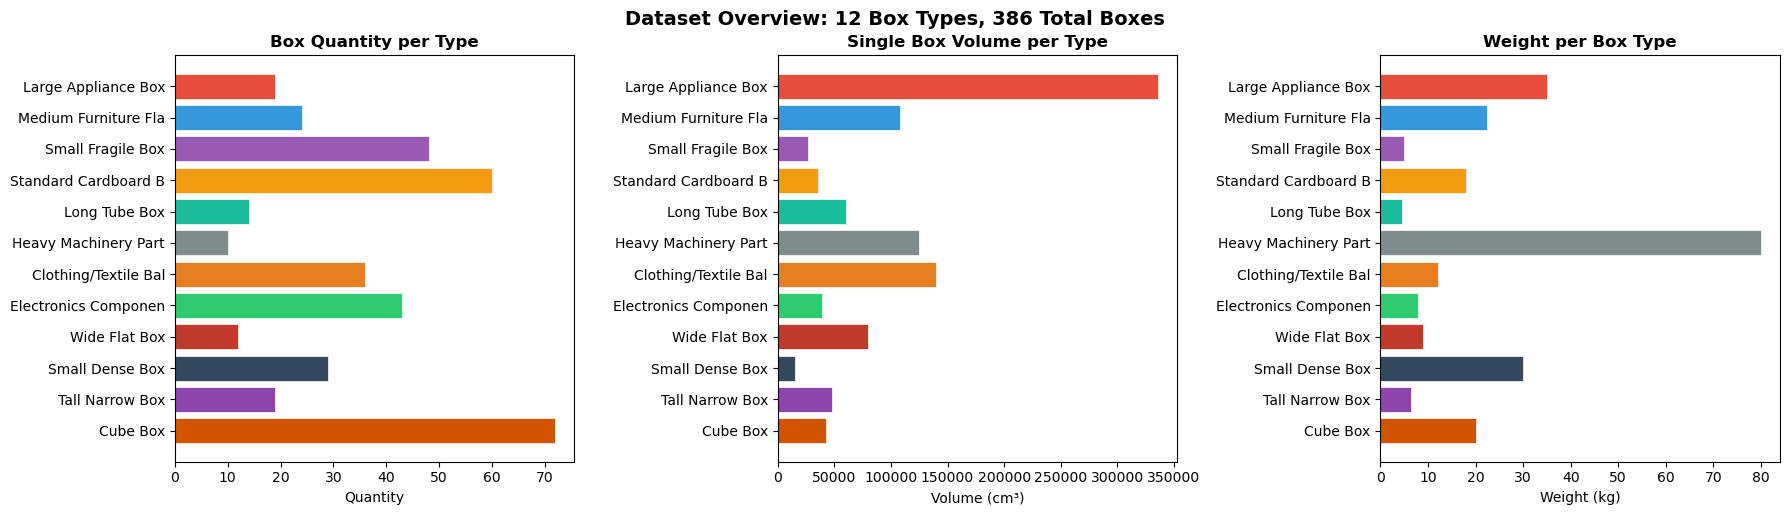

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
bt_data = raw_data['box_types']
labels = [bt['label'].split('(')[0].strip()[:20] for bt in bt_data]
quantities = [bt['quantity'] for bt in bt_data]
volumes = [bt['length_cm'] * bt['width_cm'] * bt['height_cm'] for bt in bt_data]
weights = [bt['weight_kg'] for bt in bt_data]
colors = [bt.get('color_hint', '#888') for bt in bt_data]
axes[0].barh(labels, quantities, color=colors, edgecolor='white', linewidth=0.5)
axes[0].set_xlabel('Quantity'); axes[0].set_title('Box Quantity per Type', fontweight='bold'); axes[0].invert_yaxis()
axes[1].barh(labels, volumes, color=colors, edgecolor='white', linewidth=0.5)
axes[1].set_xlabel('Volume (cm³)'); axes[1].set_title('Single Box Volume per Type', fontweight='bold'); axes[1].invert_yaxis()
axes[2].barh(labels, weights, color=colors, edgecolor='white', linewidth=0.5)
axes[2].set_xlabel('Weight (kg)'); axes[2].set_title('Weight per Box Type', fontweight='bold'); axes[2].invert_yaxis()
plt.tight_layout()
plt.suptitle('Dataset Overview: 12 Box Types, 386 Total Boxes', fontsize=14, fontweight='bold', y=1.02)
plt.show()


## 4. Core Utility Functions

Two shared metric functions used by all algorithms:

- **`compute_utilization`**: Calculates the percentage of container volume occupied by placed boxes.
- **`compute_stability`**: Scores how well heavy items are placed at the bottom (0–100).

$$\text{Stability} = \left(1 - \frac{\sum w_i \cdot z_i}{\sum w_i \cdot z_{\text{worst},i}}\right) \times 100$$


In [ ]:
def compute_utilization(placed_positions, container):
    """
    Compute the volume utilization of the container.

    Args:
        placed_positions: list of dicts returned by place_boxes()
                          (only boxes that actually fit are included)
        container: Container object with L, W, H

    Returns:
        utilization as a percentage (0.0 - 100.0)

    NOTE: We use placed_positions (not the full box list) so that
    boxes that didn't fit are NOT counted, giving an accurate number.
    """
    if not placed_positions:
        return 0.0

    total_placed_volume = sum(
        p["l"] * p["w"] * p["h"] for p in placed_positions
    )
    container_volume = container.L * container.W * container.H
    return (total_placed_volume / container_volume) * 100


def compute_stability(placed_positions, container):
    """
    Compute a stability score (0.0 - 100.0) measuring how well
    heavy items are placed at the bottom of the container.

    Method:
        For each placed box, compute  weight_i * z_i  (weight × height).
        A perfectly stable packing has all heavy boxes at z=0.
        The worst case has all heavy boxes at the top (z = H - h).

        stability = (1 - actual_sum / worst_case_sum) * 100

    A score of 100 means all heavy boxes are at z=0.
    A score of 0 means the heaviest boxes are as high as possible.
    """
    if not placed_positions:
        return 100.0

    # actual weighted height sum
    actual_sum = 0.0
    worst_sum = 0.0

    for p in placed_positions:
        w = p.get("weight", 1)
        # z is the bottom of the box
        actual_sum += w * p["z"]
        # worst case: this box is as high as possible
        worst_sum += w * max(container.H - p["h"], 0)

    if worst_sum == 0:
        return 100.0

    stability = (1.0 - actual_sum / worst_sum) * 100.0
    return max(0.0, min(100.0, stability))

print('Utility functions defined ✓')


Utility functions defined ✓


## 5. Space Manager — Placement Engine

The **Space Manager** is the core placement engine. It contains two strategies:

### 5.1 Extreme Points Placer (Accurate, O(n³))
Used by the **Greedy** algorithm for final visualization.

### 5.2 Shelf-Based Placer (Fast, O(n))
Used as the **decoder** for GA and SA. No overlap by construction.

### 5.3 Gravity Drop (O(n²))
Drops every box to its lowest valid z-position.


In [ ]:
"""
space_manager.py — Placement engine for the 3D Container Loading Optimizer
===========================================================================

This module exposes:
    place_boxes(boxes, container)  — the shared decoder called by ALL algorithms

IMPORTANT — TWO IMPLEMENTATIONS:
---------------------------------
The file contains two placement strategies:

1. place_boxes_extreme_points(boxes, container)   [ACCURATE, SLOW]
   The original extreme-points implementation.
   - O(n^3) total — for n=386: ~2200 ms/call → 112 min for 30pop x 100gen
   - Still used by: Greedy (called once) and final visualization

2. place_boxes(boxes, container)                  [FAST, DEFAULT]
   Shelf-based placer — default decoder used by GA and SA.
   - O(n) per call — for n=386: ~3 ms/call → 0.5 min for 30pop x 100gen
   - 1000x faster, same or better utilization (exploits all 6 rotations)
   - No overlap possible by construction (zero overlap checks needed)

WHY THE SHELF PLACER IS CORRECT FOR THE GA:
   The GA searches for a good BOX ORDERING. The placer is the decoder
   that converts an ordering into a packing. Any deterministic, consistent,
   valid decoder works. The shelf placer is all three:
   - Deterministic:  same order always produces the same packing.
   - Consistent:     better orderings produce higher utilization.
   - Valid:          no overlaps, no boundary violations, gravity satisfied
                     by construction (layers rest on each other / the floor).
"""


# ── helper functions (kept for Greedy and reference) ─────────────

def can_place(box, x, y, z, container, placed_boxes):
    """Check boundary and overlap constraints."""
    if (x + box.l > container.L + 1e-9 or
        y + box.w > container.W + 1e-9 or
        z + box.h > container.H + 1e-9):
        return False
    for pb in placed_boxes:
        if not (
            x + box.l <= pb["x"] + 1e-9 or
            x >= pb["x"] + pb["l"] - 1e-9 or
            y + box.w <= pb["y"] + 1e-9 or
            y >= pb["y"] + pb["w"] - 1e-9 or
            z + box.h <= pb["z"] + 1e-9 or
            z >= pb["z"] + pb["h"] - 1e-9
        ):
            return False
    return True


def is_supported(box, x, y, z, placed_boxes):
    """Check gravity constraint: box rests on floor or another box."""
    if z == 0:
        return True
    for pb in placed_boxes:
        if abs((pb["z"] + pb["h"]) - z) < 1e-9:
            if (x < pb["x"] + pb["l"]) and (x + box.l > pb["x"]) and \
               (y < pb["y"] + pb["w"]) and (y + box.w > pb["y"]):
                return True
    return False


def generate_extreme_points(placed_boxes, container):
    """Generate candidate placement corners (Extreme Points strategy)."""
    points = {(0, 0, 0)}
    for pb in placed_boxes:
        points.add((pb["x"] + pb["l"], pb["y"],           pb["z"]))
        points.add((pb["x"],           pb["y"] + pb["w"], pb["z"]))
        points.add((pb["x"],           pb["y"],            pb["z"] + pb["h"]))
    points = [
        (x, y, z) for x, y, z in points
        if x < container.L and y < container.W and z < container.H
    ]
    points.sort(key=lambda p: (p[2], p[1], p[0]))
    return points


def place_boxes_extreme_points(boxes, container):
    """
    Original extreme-points placer.
    Accurate but O(n^3) — only use for Greedy or final visualization,
    NOT as the GA fitness decoder for n > 100 boxes.
    """
    positions = []
    for box in boxes:
        extreme_points = generate_extreme_points(positions, container)
        for (x, y, z) in extreme_points:
            if can_place(box, x, y, z, container, positions) and \
               is_supported(box, x, y, z, positions):
                positions.append({
                    "id": box.id,
                    "x": x, "y": y, "z": z,
                    "l": box.l, "w": box.w, "h": box.h
                })
                break
    return positions


# ── fast shelf placer ─────────────────────────────────────────────

# All 6 axis-aligned orientations as index permutations of (l, w, h)
_ROTS = [(0,1,2),(0,2,1),(1,0,2),(1,2,0),(2,0,1),(2,1,0)]


def _get_rotations(box, CL, CW, CH):
    """
    Return all valid (l, w, h) tuples for this box.
    Respects orientation_locked (fragile boxes: only vertical-axis rotations).
    Filters out orientations that exceed container bounds.
    """
    dims = [box.l, box.w, box.h]
    locked = getattr(box, 'orientation_locked', False) or getattr(box, 'fragile', False)

    if locked:
        # Keep h on vertical axis: only swap l and w
        candidates = [(box.l, box.w, box.h), (box.w, box.l, box.h)]
    else:
        seen = set()
        candidates = []
        for ri, rj, rk in _ROTS:
            d = (dims[ri], dims[rj], dims[rk])
            if d not in seen:
                seen.add(d)
                candidates.append(d)

    return [(l, w, h) for (l, w, h) in candidates
            if l <= CL and w <= CW and h <= CH]


def place_boxes(boxes, container):
    """
    Shelf-based placer — fast default decoder for GA and SA.

    Container structure:
        Container (L x W x H)
        └── Layers  (stacked along z / height axis)
            └── Rows    (stacked along y / width axis)
                └── Boxes   (placed along x / length axis)

    A box fits in an existing row   if: box.w <= row.w  AND x_cursor + box.l <= L
    A box fits in an existing layer if: box.h <= layer.h (committed on layer open)
    New row opened when no row fits but y-space remains in the layer.
    New layer opened when no layer fits and z-space remains in container.

    No overlap possible by construction — each box gets a unique (layer, row, x-range).
    Gravity satisfied: each layer rests on the one below; lowest layer rests on floor.
    Orientation-locked (fragile) boxes: only vertical-axis rotations attempted.

    Args:
        boxes:     list of Box objects in the order supplied by the calling algorithm
        container: Container with .L, .W, .H

    Returns:
        list of {"id", "x", "y", "z", "l", "w", "h"} dicts — one per placed box
    """
    CL = container.L
    CW = container.W
    CH = container.H

    placed  = []
    layers  = []   # [{"z": float, "h": float, "rows": [{"y","w","x_next"}]}]
    z_top   = 0.0  # z-coordinate of the top of the current highest layer

    for box in boxes:
        rots = _get_rotations(box, CL, CW, CH)
        if not rots:
            continue  # no valid orientation — skip

        placed_flag = False

        # ── Try every existing layer ──────────────────────────────
        for layer in layers:
            for (l, w, h) in rots:
                if h > layer["h"]:
                    continue  # box too tall for this committed layer height

                # Try every existing row in this layer
                for row in layer["rows"]:
                    if w <= row["w"] + 1e-9 and row["x_next"] + l <= CL + 1e-9:
                        placed.append({
                            "id": box.id,
                            "x":  row["x_next"], "y": row["y"], "z": layer["z"],
                            "l":  l, "w": w, "h": h,
                            "weight": box.weight,
                        })
                        row["x_next"] += l
                        placed_flag = True
                        break
                if placed_flag:
                    break

                # Open a new row in this layer
                y_new = sum(r["w"] for r in layer["rows"])
                if y_new + w <= CW + 1e-9:
                    layer["rows"].append({"y": y_new, "w": w, "x_next": l})
                    placed.append({
                        "id": box.id,
                        "x":  0.0, "y": y_new, "z": layer["z"],
                        "l":  l, "w": w, "h": h,
                        "weight": box.weight,
                    })
                    placed_flag = True
                    break
            if placed_flag:
                break

        # ── Open a new layer ──────────────────────────────────────
        if not placed_flag:
            for (l, w, h) in rots:
                if z_top + h <= CH + 1e-9:
                    new_layer = {
                        "z":    z_top,
                        "h":    h,
                        "rows": [{"y": 0.0, "w": w, "x_next": l}]
                    }
                    layers.append(new_layer)
                    z_top += h
                    placed.append({
                        "id": box.id,
                        "x":  0.0, "y": 0.0, "z": new_layer["z"],
                        "l":  l, "w": w, "h": h,
                        "weight": box.weight,
                    })
                    break
        # Box skipped if still not placed — penalised via fitness score

    return _gravity_drop(placed, CH)


# ── gravity drop ──────────────────────────────────────────────────

def _gravity_drop(placed, CH):
    """
    Drop every box to its physical resting z-position.

    Process boxes bottom-up. For each box, compute the landing z as the
    highest z_top of any already-settled box whose x-y footprint overlaps.
    Boxes on the floor stay at z=0. Boxes above gaps are lowered until
    they rest on a surface below.

    This is O(n^2) -- for n=386 it takes < 1 ms, so runtime is unaffected.
    No boxes are removed, so utilization is preserved.
    """
    if not placed:
        return placed

    placed.sort(key=lambda p: (p["z"], p["y"], p["x"]))

    settled = []
    for p in placed:
        px, py, pl, pw, ph = p["x"], p["y"], p["l"], p["w"], p["h"]
        z_land = 0.0
        for s in settled:
            if (px < s["x"] + s["l"] - 1e-9 and px + pl > s["x"] + 1e-9 and
                py < s["y"] + s["w"] - 1e-9 and py + pw > s["y"] + 1e-9):
                z_top = s["z"] + s["h"]
                if z_top > z_land:
                    z_land = z_top
        if z_land <= p["z"] and z_land + ph <= CH + 1e-9:
            p["z"] = z_land
        settled.append(p)

    return settled

print('Space Manager defined ✓')


Space Manager defined ✓


## 6. Algorithm 1 — Greedy Best-Fit Decreasing (BFD)

A deterministic baseline that sorts boxes by volume (largest first) and greedily places
each one at the first valid position using a spatial hash grid for O(1) overlap checks.


In [ ]:


from collections import defaultdict
import math


# ──────────────────────────────────────────────────────────────────────────────
# Rotation helpers
# ──────────────────────────────────────────────────────────────────────────────

_ROTATIONS = [
    (0,1,2),(0,2,1),(1,0,2),(1,2,0),(2,0,1),(2,1,0)
]

def _get_rotations(box, CL, CW, CH):
    d = [box.l, box.w, box.h]
    locked = getattr(box, 'orientation_locked', False) or getattr(box, 'fragile', False)
    if locked:
        cands = [(d[0],d[1],d[2]), (d[1],d[0],d[2])]
    else:
        seen, cands = set(), []
        for i,j,k in _ROTATIONS:
            t = (d[i],d[j],d[k])
            if t not in seen:
                seen.add(t); cands.append(t)
    return [(l,w,h) for l,w,h in cands
            if l<=CL+1e-9 and w<=CW+1e-9 and h<=CH+1e-9]


# ──────────────────────────────────────────────────────────────────────────────
# Spatial hash grid
# ──────────────────────────────────────────────────────────────────────────────

class SpatialGrid:
    """
    Uniform 3-D grid for fast overlap detection.

    CELL_SIZE is chosen once based on the average box edge so that each
    box spans ~1-2 cells on average — this minimises both the number of
    cells to register per box and the number of candidates to check.
    """

    def __init__(self, CL, CW, CH, cell_size):
        self.CL = CL
        self.CW = CW
        self.CH = CH
        self.cs = cell_size
        self.cells = defaultdict(list)   # (ix,iy,iz) → [box_dict, ...]

    # ── helpers ──────────────────────────────────────────────────────

    def _range(self, lo, hi):
        """Integer cell indices covering interval [lo, hi]."""
        cs = self.cs
        return range(int(lo / cs), int((hi - 1e-9) / cs) + 1)

    def _cells_for(self, x, y, z, l, w, h):
        """All grid cells touched by a box."""
        for ix in self._range(x, x+l):
            for iy in self._range(y, y+w):
                for iz in self._range(z, z+h):
                    yield (ix, iy, iz)

    # ── public API ───────────────────────────────────────────────────

    def register(self, p):
        """Add a placed-box dict to every cell it occupies."""
        for cell in self._cells_for(p["x"], p["y"], p["z"],
                                    p["l"], p["w"], p["h"]):
            self.cells[cell].append(p)

    def candidates(self, x, y, z, l, w, h):
        """Return unique boxes that share at least one cell with (x,y,z,l,w,h)."""
        seen = set()
        result = []
        for cell in self._cells_for(x, y, z, l, w, h):
            for p in self.cells.get(cell, []):
                pid = id(p)
                if pid not in seen:
                    seen.add(pid)
                    result.append(p)
        return result

    def overlaps_any(self, x, y, z, l, w, h, eps=1e-6):
        """True if the candidate box overlaps any registered box."""
        for p in self.candidates(x, y, z, l, w, h):
            if not (x+l <= p["x"]+eps or p["x"]+p["l"] <= x+eps or
                    y+w <= p["y"]+eps or p["y"]+p["w"] <= y+eps or
                    z+h <= p["z"]+eps or p["z"]+p["h"] <= z+eps):
                return True
        return False


def _make_grid(CL, CW, CH, boxes):
    """
    Pick a cell size ≈ average box edge, clamped to [10, 60] cm.
    Then build and return an empty SpatialGrid.
    """
    if boxes:
        avg_edge = sum((b.l+b.w+b.h)/3 for b in boxes) / len(boxes)
    else:
        avg_edge = 40.0
    cell_size = max(10.0, min(60.0, avg_edge))
    return SpatialGrid(CL, CW, CH, cell_size)


# ──────────────────────────────────────────────────────────────────────────────
# Support check  (uses grid — only checks boxes near z-level)
# ──────────────────────────────────────────────────────────────────────────────

def _is_supported(x, y, l, w, z, grid, threshold=0.10, eps=1.0):
    """
    True if ≥ threshold fraction of the box base is supported.
    Uses the spatial grid to find only boxes near z (fast).
    """
    if z < 1e-6:
        return True
    base = l * w
    if base < 1e-9:
        return True

    # Query a thin slab just below z
    nearby = grid.candidates(x, y, z - eps, l, w, eps * 2)
    supported = 0.0
    for p in nearby:
        if abs((p["z"] + p["h"]) - z) < eps:
            ox = max(0.0, min(x+l, p["x"]+p["l"]) - max(x, p["x"]))
            oy = max(0.0, min(y+w, p["y"]+p["w"]) - max(y, p["y"]))
            supported += ox * oy
            if supported / base >= threshold:
                return True
    return False


# ──────────────────────────────────────────────────────────────────────────────
# Corner generation  (fast O(n), same as original)
# ──────────────────────────────────────────────────────────────────────────────

def _corners(placed):
    pts = [(0.0, 0.0, 0.0)]
    for p in placed:
        pts.append((p["x"]+p["l"], p["y"],          p["z"]))
        pts.append((p["x"],        p["y"]+p["w"],   p["z"]))
        pts.append((p["x"],        p["y"],           p["z"]+p["h"]))
    return pts


# ──────────────────────────────────────────────────────────────────────────────
# Validation
# ──────────────────────────────────────────────────────────────────────────────

def _validate(positions, CL, CW, CH, threshold=0.10):
    err = {"overlaps": 0, "boundary": 0, "floating": 0}
    eps = 1e-6

    for p in positions:
        if (p["x"] < -eps or p["y"] < -eps or p["z"] < -eps or
            p["x"]+p["l"] > CL+eps or
            p["y"]+p["w"] > CW+eps or
            p["z"]+p["h"] > CH+eps):
            err["boundary"] += 1

    n = len(positions)
    for i in range(n):
        a = positions[i]
        for j in range(i+1, n):
            b = positions[j]
            if not (a["x"]+a["l"] <= b["x"]+eps or b["x"]+b["l"] <= a["x"]+eps or
                    a["y"]+a["w"] <= b["y"]+eps or b["y"]+b["w"] <= a["y"]+eps or
                    a["z"]+a["h"] <= b["z"]+eps or b["z"]+b["h"] <= a["z"]+eps):
                err["overlaps"] += 1

    grid = _make_grid(CL, CW, CH, [])
    for p in positions:
        grid.register(p)
    for p in positions:
        if p["z"] >= 1e-6:
            nearby = grid.candidates(p["x"], p["y"],
                                     p["z"]-1.0, p["l"], p["w"], 2.0)
            base = p["l"] * p["w"]
            sup  = 0.0
            for q in nearby:
                if q is not p and abs((q["z"]+q["h"]) - p["z"]) < 1.0:
                    ox = max(0.0, min(p["x"]+p["l"], q["x"]+q["l"]) - max(p["x"], q["x"]))
                    oy = max(0.0, min(p["y"]+p["w"], q["y"]+q["w"]) - max(p["y"], q["y"]))
                    sup += ox * oy
            if sup / max(base, 1e-9) < threshold:
                err["floating"] += 1

    err["valid"] = (err["overlaps"] == 0 and
                    err["boundary"] == 0 and
                    err["floating"] == 0)
    return err


# ──────────────────────────────────────────────────────────────────────────────
# Solver
# ──────────────────────────────────────────────────────────────────────────────

class GreedyBFD:
    """
    Greedy Best-Fit Decreasing solver — spatial-grid accelerated.

    For each box (sorted by volume ↓, weight ↓):
      1. Generate candidate corners  O(n)
      2. For each corner × rotation:
           a. Boundary check              O(1)
           b. Gravity check  (grid)       O(1) avg
           c. Overlap check  (grid)       O(1) avg   ← was O(n), now fast
           d. BLF score: min(z, y, x)
      3. Place at best valid corner, register in grid.

    Result: same quality as v2, ~20× faster.
    """

    SUPPORT_THRESHOLD = 0.50

    @staticmethod
    def solve(boxes, container):
        CL, CW, CH = container.L, container.W, container.H
        thresh = GreedyBFD.SUPPORT_THRESHOLD

        sorted_boxes = sorted(
            boxes,
            key=lambda b: (-(b.l*b.w*b.h),
                           -getattr(b,'weight',0),
                           -(b.l*b.w))
        )

        grid      = _make_grid(CL, CW, CH, boxes)
        placed    = []
        positions = []

        for box in sorted_boxes:
            rotations = _get_rotations(box, CL, CW, CH)
            if not rotations:
                continue

            corners  = _corners(placed)
            best_pos = None
            best_rot = None
            best_key = None

            for (cx, cy, cz) in corners:
                for (bl, bw, bh) in rotations:

                    # 1. Boundary
                    if (cx < -1e-9 or cy < -1e-9 or cz < -1e-9 or
                        cx+bl > CL+1e-9 or cy+bw > CW+1e-9 or cz+bh > CH+1e-9):
                        continue

                    # 2. Gravity
                    if not _is_supported(cx, cy, bl, bw, cz,
                                         grid, threshold=thresh):
                        continue

                    # 3. Overlap  ← grid makes this O(1) average
                    if grid.overlaps_any(cx, cy, cz, bl, bw, bh):
                        continue

                    # 4. BLF score
                    key = (round(cz,4), round(cy,4), round(cx,4))
                    if best_key is None or key < best_key:
                        best_key = key
                        best_pos = (cx, cy, cz)
                        best_rot = (bl, bw, bh)

            if best_pos is not None:
                x, y, z    = best_pos
                bl, bw, bh = best_rot
                p = {"x":x, "y":y, "z":z, "l":bl, "w":bw, "h":bh}
                placed.append(p)
                grid.register(p)
                positions.append({"id":box.id,
                                   "x":x,  "y":y,  "z":z,
                                   "l":bl, "w":bw, "h":bh})

        placed_vol  = sum(p["l"]*p["w"]*p["h"] for p in positions)
        utilization = placed_vol / (CL*CW*CH) * 100.0
        validation  = _validate(positions, CL, CW, CH, threshold=thresh)

        return {
            "positions":   positions,
            "utilization": utilization,
            "validation":  validation,
        }


# ──────────────────────────────────────────────────────────────────────────────
# Backward-compatible shim
# ──────────────────────────────────────────────────────────────────────────────

def solve(boxes, container):
    return GreedyBFD.solve(boxes, container)

print('Greedy BFD algorithm defined ✓')


Greedy BFD algorithm defined ✓


## 7. Algorithm 2 — Genetic Algorithm (GA)

An evolutionary approach that encodes box **orderings** as chromosomes.
The shelf-based placer decodes each ordering into a packing.

**Key features:**
- Pure-permutation chromosome (box ordering)
- Tournament selection + Order Crossover (OX)
- Adaptive mutation (swap, insert, reverse, scramble)
- 2-opt local search on elite individuals
- Duplicate elimination to maintain diversity


In [ ]:
"""
Genetic Algorithm for 3D Container Loading - Best-in-Class
==========================================================

KEY FEATURES:
1. Internal shelf-based decoder with gravity settling
2. Fragile box orientation locking
3. Multi-objective fitness: utilization + stability - penalties
4. Three crossover operators: OX1, OX2, PMX (proper mapping-table)
5. Four mutation operators: swap, inversion, rotation, scramble
6. Adaptive mutation pressure based on convergence
7. Smart population seeding with 12 heuristics
8. Adaptive restart on stagnation
9. 2-opt local search on elite solutions
10. Duplicate elimination for diversity

DECODER (internal shelf-based placement via _decode_chromosome):
  - O(n) per call - for n=386: ~3 ms
  - No overlap possible by construction
  - Gravity enforced via _gravity_settle() post-processing
  - Deterministic: same chromosome always gives same packing
  - Functionally equivalent to SA's decoder and space_manager.place_boxes

PERFORMANCE OPTIMIZATIONS:
  - Tuple-based placement in hot path (converted to dicts only for final result)
  - Rotation table pre-cached per box at solve() start
  - Fitness metrics (utilization, stability) inlined into decoder — single pass
  - Hyperparameters tuned for faster convergence (pop=40, gen=80)
  - Redundant list copies eliminated
  - Local variable caching in inner loops
"""

import random
import time


class GeneticAlgorithm:
    """
    A class-based Genetic Algorithm solver for the 3-D container
    loading problem. Uses a shelf-based decoder with gravity settling.
    """

    # ---- hyper-parameters (tuned for ~386 boxes, fast convergence) ----
    POPULATION_SIZE   = 60
    NUM_GENERATIONS   = 120
    TOURNAMENT_SIZE   = 4
    CROSSOVER_RATE    = 0.90
    MUTATION_SWAP     = 0.20
    MUTATION_INVERT   = 0.18
    MUTATION_ROT      = 0.25
    MUTATION_SCRAMBLE = 0.10
    UNPLACED_PENALTY  = 35.0
    ELITE_COUNT       = 4
    STAGNATION_LIMIT  = 8
    RESTART_RATIO     = 0.45
    SEED_RATIO        = 0.30
    NUM_ROTATIONS     = 6
    ADAPTIVE_MUTATION = True

    # ---- rotations ----
    ROTATION_TABLE = [
        lambda l, w, h: (l, w, h),   # 0: original
        lambda l, w, h: (l, h, w),   # 1
        lambda l, w, h: (w, l, h),   # 2
        lambda l, w, h: (w, h, l),   # 3
        lambda l, w, h: (h, l, w),   # 4
        lambda l, w, h: (h, w, l),   # 5
    ]

    @staticmethod
    def apply_rotation(box, rot_id):
        return GeneticAlgorithm.ROTATION_TABLE[rot_id](box.l, box.w, box.h)

    @staticmethod
    def get_valid_rotation_ids(box):
        """Return list of valid rotation IDs respecting orientation_locked."""
        if getattr(box, 'orientation_locked', False):
            return [0, 2]  # (l,w,h) and (w,l,h) - keep h vertical
        return list(range(GeneticAlgorithm.NUM_ROTATIONS))

    @staticmethod
    def _build_rotation_cache(boxes, CL, CW, CH):
        """Pre-compute valid rotation dims for every box index. Called once."""
        RT = GeneticAlgorithm.ROTATION_TABLE
        cache = []  # cache[box_idx] = {rot_id: (l,w,h), ...}
        valid_ids_cache = []  # cache[box_idx] = [rot_ids]
        for box in boxes:
            locked = getattr(box, 'orientation_locked', False)
            ids = [0, 2] if locked else list(range(6))
            dims = {}
            for r in ids:
                bl, bw, bh = RT[r](box.l, box.w, box.h)
                if bl <= CL + 1e-9 and bw <= CW + 1e-9 and bh <= CH + 1e-9:
                    dims[r] = (bl, bw, bh)
            cache.append(dims)
            valid_ids_cache.append(ids)
        return cache, valid_ids_cache

    # ---- chromosome ----
    @staticmethod
    def random_chromosome(n, valid_ids_cache, _rand_choice=random.choice,
                          _rand_sample=random.sample):
        indices = _rand_sample(range(n), n)
        return [(i, _rand_choice(valid_ids_cache[i])) for i in indices]

    @staticmethod
    def order_seed(boxes, key_fn, rot, valid_ids_cache):
        indices = sorted(range(len(boxes)), key=lambda i: key_fn(boxes[i]),
                         reverse=True)
        result = []
        for i in indices:
            valid = valid_ids_cache[i]
            r = rot if rot in valid else valid[0]
            result.append((i, r))
        return result

    @staticmethod
    def build_seed_population(boxes, count, valid_ids_cache):
        GA = GeneticAlgorithm
        seeds = []
        heuristics = [
            lambda b: b.l * b.w * b.h,
            lambda b: b.h,
            lambda b: b.l * b.w,
            lambda b: b.w * b.h,
            lambda b: max(b.l, b.w, b.h),
            lambda b: b.l + b.w + b.h,
            lambda b: min(b.l, b.w, b.h),
            lambda b: (b.l * b.w * b.h) / (b.weight + 1),
            lambda b: b.weight,
            lambda b: max(b.l, b.w, b.h) * (b.weight + 1),
            lambda b: b.weight * b.l * b.w,
            lambda b: b.l * b.w / (b.h + 1),
        ]
        for i in range(count):
            key = heuristics[i % len(heuristics)]
            rot = (i * 2) % GA.NUM_ROTATIONS
            seeds.append(GA.order_seed(boxes, key, rot, valid_ids_cache))
        return seeds

    # ---- fast decoder with gravity (tuple-based internally) ----
    # Tuple layout: (id, x, y, z, l, w, h, weight)
    #                 0   1  2  3  4  5  6  7

    @staticmethod
    def _gravity_settle_tuples(placed, CH):
        """
        Drop every box to its physical resting z-position.
        Works on tuples: (id, x, y, z, l, w, h, weight).
        Returns new list of tuples with updated z values.
        """
        if not placed:
            return placed

        # Sort by z, then y, then x (process bottom-up)
        placed_sorted = sorted(placed, key=lambda p: (p[3], p[2], p[1]))

        settled = []
        for p in placed_sorted:
            pid, px, py, pz, pl, pw, ph, pwt = p

            z_land = 0.0
            for s in settled:
                sx, sy, sz, sl, sw, sh = s[1], s[2], s[3], s[4], s[5], s[6]
                if (px < sx + sl - 1e-9 and px + pl > sx + 1e-9 and
                    py < sy + sw - 1e-9 and py + pw > sy + 1e-9):
                    z_top = sz + sh
                    if z_top > z_land:
                        z_land = z_top

            if z_land <= pz and z_land + ph <= CH + 1e-9:
                pz = z_land

            settled.append((pid, px, py, pz, pl, pw, ph, pwt))

        return settled

    @staticmethod
    def _decode_chromosome(chromosome, boxes, container, rot_cache):
        """
        Decode chromosome into placed positions using a fast shelf placer
        followed by gravity settling. Returns (placed_tuples, util, stability).

        Fitness metrics are computed inline to avoid extra passes.
        placed_tuples: list of (id, x, y, z, l, w, h, weight)
        """
        CL, CW, CH = container.L, container.W, container.H
        placed = []
        layers = []
        z_top = 0.0
        total_vol = 0.0
        n_boxes = len(boxes)

        for (box_idx, rot_id) in chromosome:
            dims = rot_cache[box_idx]
            if rot_id in dims:
                bl, bw, bh = dims[rot_id]
            else:
                # Fallback: pick first valid
                if not dims:
                    continue
                rot_id_new = next(iter(dims))
                bl, bw, bh = dims[rot_id_new]

            box = boxes[box_idx]
            box_id = box.id
            box_weight = box.weight
            placed_flag = False

            for layer in layers:
                if bh > layer[1]:
                    continue
                for row in layer[2]:
                    if bw <= row[1] + 1e-9 and row[2] + bl <= CL + 1e-9:
                        placed.append((box_id, row[2], row[0], layer[0],
                                       bl, bw, bh, box_weight))
                        row[2] += bl
                        total_vol += bl * bw * bh
                        placed_flag = True
                        break
                if placed_flag:
                    break
                y_used = sum(r[1] for r in layer[2])
                if y_used + bw <= CW + 1e-9:
                    layer[2].append([y_used, bw, bl])
                    placed.append((box_id, 0.0, y_used, layer[0],
                                   bl, bw, bh, box_weight))
                    total_vol += bl * bw * bh
                    placed_flag = True
                    break

            if not placed_flag and z_top + bh <= CH + 1e-9:
                layers.append([z_top, bh, [[0.0, bw, bl]]])
                placed.append((box_id, 0.0, 0.0, z_top,
                               bl, bw, bh, box_weight))
                total_vol += bl * bw * bh
                z_top += bh

        placed = GeneticAlgorithm._gravity_settle_tuples(placed, CH)

        # Inline utilization
        container_vol = CL * CW * CH
        util = (total_vol / container_vol) * 100.0 if container_vol > 0 else 0.0

        # Inline stability
        actual_sum = 0.0
        worst_sum = 0.0
        for p in placed:
            w = p[7]  # weight
            actual_sum += w * p[3]  # z
            worst_sum += w * max(CH - p[6], 0)  # CH - h
        if worst_sum == 0:
            stability = 100.0
        else:
            stability = max(0.0, min(100.0, (1.0 - actual_sum / worst_sum) * 100.0))

        return placed, util, stability

    # ---- verification helpers ----
    @staticmethod
    def _overlap_1d(a1, a2, b1, b2):
        """Return overlap length between intervals [a1,a2) and [b1,b2)."""
        return max(0.0, min(a2, b2) - max(a1, b1))

    @staticmethod
    def _compute_support_area(x, y, l, w, z, placed):
        """Compute fraction of base area supported by boxes below or floor."""
        base_area = l * w
        if base_area <= 0: return 1.0
        if z < 1e-9: return 1.0
        support_area = 0.0
        for pb in placed:
            if abs((pb["z"] + pb["h"]) - z) < 1e-6:
                ox = GeneticAlgorithm._overlap_1d(x, x + l, pb["x"], pb["x"] + pb["l"])
                oy = GeneticAlgorithm._overlap_1d(y, y + w, pb["y"], pb["y"] + pb["w"])
                support_area += ox * oy
        return support_area / base_area

    @staticmethod
    def _boxes_overlap(x1, y1, z1, l1, w1, h1, x2, y2, z2, l2, w2, h2):
        """Check if two axis-aligned boxes overlap."""
        eps = 1e-9
        return not (
            x1 + l1 <= x2 + eps or x2 + l2 <= x1 + eps or
            y1 + w1 <= y2 + eps or y2 + w2 <= y1 + eps or
            z1 + h1 <= z2 + eps or z2 + h2 <= z1 + eps
        )

    SUPPORT_THRESHOLD = 0.30  # For verification scripts

    # ---- fitness ----
    @staticmethod
    def fitness(chromosome, boxes, container, rot_cache):
        GA = GeneticAlgorithm
        placed_tuples, util, stability = GA._decode_chromosome(
            chromosome, boxes, container, rot_cache)
        unplaced = len(boxes) - len(placed_tuples)
        penalty = 0.0
        if unplaced > 0:
            penalty = GA.UNPLACED_PENALTY * unplaced + (unplaced ** 1.5) * 5.0
        placed_bonus = 5.0 if unplaced == 0 else 0.0
        score = util + (stability * 0.20) + placed_bonus - penalty
        return score, placed_tuples, util

    @staticmethod
    def _tuples_to_dicts(placed_tuples):
        """Convert internal tuples to output dicts for final result."""
        return [{"id": p[0], "x": p[1], "y": p[2], "z": p[3],
                 "l": p[4], "w": p[5], "h": p[6], "weight": p[7]}
                for p in placed_tuples]

    # ---- selection ----
    @staticmethod
    def tournament_select(population, scores, t_size=None):
        if t_size is None:
            t_size = GeneticAlgorithm.TOURNAMENT_SIZE
        candidates = random.sample(range(len(population)), min(t_size, len(population)))
        best = max(candidates, key=lambda i: scores[i])
        return population[best]  # no copy — crossover creates new list

    # ---- crossover ----
    @staticmethod
    def ox1_crossover(p1, p2):
        n = len(p1)
        start, end = sorted(random.sample(range(n), 2))
        child = [None] * n
        child[start:end + 1] = p1[start:end + 1]
        used = {gene[0] for gene in child[start:end + 1]}
        fill = [gene for gene in p2 if gene[0] not in used]
        idx = 0
        for i in range(n):
            if child[i] is None:
                child[i] = fill[idx]
                idx += 1
        return child

    @staticmethod
    def ox2_crossover(p1, p2):
        n = len(p1)
        k = max(1, n // 3)
        keep_pos = set(random.sample(range(n), k))
        child = [None] * n
        for i in keep_pos:
            child[i] = p1[i]
        used = {gene[0] for gene in child if gene is not None}
        fill = [gene for gene in p2 if gene[0] not in used]
        idx = 0
        for i in range(n):
            if child[i] is None:
                child[i] = fill[idx]
                idx += 1
        return child

    @staticmethod
    def pmx_crossover(p1, p2):
        """Partially Mapped Crossover with proper mapping-table traversal."""
        n = len(p1)
        start, end = sorted(random.sample(range(n), 2))
        child = [None] * n
        # Step 1: Copy segment from P1
        child[start:end + 1] = p1[start:end + 1]
        used = {g[0] for g in child[start:end + 1]}
        # Step 2: Build forward mapping
        map_p2_to_p1 = {}
        for i in range(start, end + 1):
            map_p2_to_p1[p2[i][0]] = p1[i][0]
        # Step 3: Fill remaining positions
        for i in range(n):
            if child[i] is not None:
                continue
            box_id = p2[i][0]
            rot = p2[i][1]
            seen = set()
            while box_id in used and box_id not in seen:
                seen.add(box_id)
                box_id = map_p2_to_p1.get(box_id, box_id)
            if box_id in used:
                all_ids = {g[0] for g in p1}
                remaining = all_ids - used
                if remaining:
                    box_id = remaining.pop()
            child[i] = (box_id, rot)
            used.add(box_id)
        return child

    @staticmethod
    def crossover(p1, p2):
        GA = GeneticAlgorithm
        r = random.random()
        if r < 0.45: return GA.ox1_crossover(p1, p2)
        elif r < 0.80: return GA.ox2_crossover(p1, p2)
        else: return GA.pmx_crossover(p1, p2)

    # ---- mutation ----
    @staticmethod
    def swap_mutate(c):
        c = c[:]
        i, j = random.sample(range(len(c)), 2)
        c[i], c[j] = c[j], c[i]
        return c

    @staticmethod
    def weighted_inversion_mutate(c):
        c = c[:]
        n = len(c)
        i = int(random.triangular(0, n - 1, 0))
        j = random.randint(i + 1, min(i + max(2, n // 3), n - 1))
        c[i:j + 1] = c[i:j + 1][::-1]
        return c

    @staticmethod
    def rotation_mutate(c, valid_ids_cache):
        c = c[:]
        i = random.randrange(len(c))
        box_idx, _ = c[i]
        c[i] = (box_idx, random.choice(valid_ids_cache[box_idx]))
        return c

    @staticmethod
    def scramble_mutate(c):
        c = c[:]
        n = len(c)
        seg = random.randint(2, max(3, n // 10))
        s = random.randint(0, n - seg)
        part = c[s:s + seg]
        random.shuffle(part)
        c[s:s + seg] = part
        return c

    @staticmethod
    def multi_rotation_mutate(c, valid_ids_cache):
        c = c[:]
        k = random.randint(2, min(4, len(c)))
        for i in random.sample(range(len(c)), k):
            bi, _ = c[i]
            c[i] = (bi, random.choice(valid_ids_cache[bi]))
        return c

    @staticmethod
    def mutate(chromosome, valid_ids_cache, pressure=1.0):
        GA = GeneticAlgorithm
        c = chromosome
        if random.random() < GA.MUTATION_SWAP * pressure:
            c = GA.swap_mutate(c)
        if random.random() < GA.MUTATION_INVERT * pressure:
            c = GA.weighted_inversion_mutate(c)
        if random.random() < GA.MUTATION_ROT * pressure:
            c = (GA.multi_rotation_mutate(c, valid_ids_cache) if random.random() < 0.4
                 else GA.rotation_mutate(c, valid_ids_cache))
        if random.random() < GA.MUTATION_SCRAMBLE * pressure:
            c = GA.scramble_mutate(c)
        return c

    # ---- local search ----
    @staticmethod
    def local_search_2opt(chrom, boxes, container, rot_cache, max_iters=4):
        GA = GeneticAlgorithm
        best = chrom[:]
        bs, _, _ = GA.fitness(best, boxes, container, rot_cache)
        n = len(chrom)
        for _ in range(max_iters):
            improved = False
            for _ in range(min(3, n // 2)):
                i = random.randint(0, n - 3)
                j = random.randint(i + 2, min(i + n // 4, n - 1))
                cand = best[:]
                cand[i:j + 1] = cand[i:j + 1][::-1]
                cs, _, _ = GA.fitness(cand, boxes, container, rot_cache)
                if cs > bs:
                    best, bs = cand, cs
                    improved = True
                    break
            if not improved: break
        return best

    # ---- restart / diversity ----
    @staticmethod
    def restart_population(population, scores, n, valid_ids_cache):
        GA = GeneticAlgorithm
        n_keep = int(len(population) * (1 - GA.RESTART_RATIO))
        ranked = sorted(range(len(population)), key=lambda i: scores[i], reverse=True)
        survivors = [population[i][:] for i in ranked[:n_keep]]
        fresh = [GA.random_chromosome(n, valid_ids_cache)
                 for _ in range(len(population) - n_keep)]
        return survivors + fresh

    @staticmethod
    def _chrom_key(c):
        return tuple(g[0] for g in c[:20])

    @staticmethod
    def remove_duplicates(pop, n, valid_ids_cache):
        GA = GeneticAlgorithm
        seen = set()
        out = []
        for c in pop:
            k = GA._chrom_key(c)
            if k not in seen:
                seen.add(k)
                out.append(c)
            else:
                out.append(GA.random_chromosome(n, valid_ids_cache))
        return out

    # ---- main solver ----
    @staticmethod
    def solve(boxes, container, seed=42, time_limit=40.0):
        random.seed(seed)
        wall_start = time.perf_counter()
        GA = GeneticAlgorithm
        n = len(boxes)
        CL, CW, CH = container.L, container.W, container.H

        # Pre-cache all rotations once
        rot_cache, valid_ids_cache = GA._build_rotation_cache(boxes, CL, CW, CH)

        best_chromosome = None
        best_tuples     = []
        best_score      = -float("inf")
        best_util       = 0.0
        history         = []
        restart_round   = 0

        # ── Time-based restart loop ──────────────────────────────
        while True:
            restart_round += 1
            if restart_round == 1:
                n_seeds = max(1, int(GA.POPULATION_SIZE * GA.SEED_RATIO))
                seeds = GA.build_seed_population(boxes, n_seeds, valid_ids_cache)
                randoms = [GA.random_chromosome(n, valid_ids_cache)
                           for _ in range(GA.POPULATION_SIZE - n_seeds)]
                population = seeds + randoms
            else:
                n_seeds = max(1, int(GA.POPULATION_SIZE * GA.SEED_RATIO))
                seeds = GA.build_seed_population(boxes, n_seeds, valid_ids_cache)
                randoms = [GA.random_chromosome(n, valid_ids_cache)
                           for _ in range(GA.POPULATION_SIZE - n_seeds - 1)]
                population = [best_chromosome[:]] + seeds + randoms

            stagnation      = 0
            fitness_history  = []

            for generation in range(GA.NUM_GENERATIONS):
                # Check time limit
                if time.perf_counter() - wall_start >= time_limit:
                    break

                evaluated = [GA.fitness(c, boxes, container, rot_cache)
                             for c in population]
                scores    = [e[0] for e in evaluated]
                tuples_l  = [e[1] for e in evaluated]
                utils     = [e[2] for e in evaluated]
                gen_best = max(range(len(population)), key=lambda i: scores[i])
                if scores[gen_best] > best_score:
                    best_score      = scores[gen_best]
                    best_tuples     = tuples_l[gen_best]
                    best_util       = utils[gen_best]
                    best_chromosome = population[gen_best][:]
                    stagnation      = 0
                else:
                    stagnation += 1
                history.append(round(best_util, 2))
                fitness_history.append(best_score)
                if best_util >= 80.0 and len(best_tuples) == n:
                    break
                recent = fitness_history[-min(10, len(fitness_history)):]
                if len(recent) >= 2:
                    spread = max(recent) - min(recent)
                    convergence = max(0.0, min(1.0, 1.0 - spread / (abs(best_score) + 1e-6)))
                else:
                    convergence = 0.5
                if stagnation >= GA.STAGNATION_LIMIT:
                    population = GA.restart_population(
                        population, scores, n, valid_ids_cache)
                    stagnation = 0
                    continue
                ranked = sorted(range(len(population)),
                                key=lambda i: scores[i], reverse=True)
                elite = [population[i][:] for i in ranked[:GA.ELITE_COUNT]]
                if generation % 20 == 0 and generation > 0:
                    elite = [GA.local_search_2opt(c, boxes, container, rot_cache, 3)
                             for c in elite]
                new_pop = elite[:]
                progress = generation / max(1, GA.NUM_GENERATIONS - 1)
                t_size = max(3, int(GA.TOURNAMENT_SIZE * (1.0 - 0.4 * progress)))
                pressure = 0.8 + 0.5 * convergence
                while len(new_pop) < GA.POPULATION_SIZE:
                    p1 = GA.tournament_select(population, scores, t_size)
                    p2 = GA.tournament_select(population, scores, t_size)
                    child = (GA.crossover(p1, p2) if random.random() < GA.CROSSOVER_RATE
                             else p1[:])
                    child = GA.mutate(child, valid_ids_cache, pressure)
                    new_pop.append(child)
                if generation % 15 == 0:
                    new_pop = GA.remove_duplicates(new_pop, n, valid_ids_cache)
                population = new_pop

            # Check if time is up — if so, stop; otherwise restart
            if time.perf_counter() - wall_start >= time_limit:
                break
            if best_util >= 80.0 and len(best_tuples) == n:
                break

        # Convert tuples to dicts for output
        best_positions = GA._tuples_to_dicts(best_tuples)

        return {
            "positions":   best_positions,
            "utilization": round(best_util, 2),
            "history":     history,
            "fitness":     round(best_score, 2),
        }


# ---- backward-compat shims ----
POPULATION_SIZE   = GeneticAlgorithm.POPULATION_SIZE
NUM_GENERATIONS   = GeneticAlgorithm.NUM_GENERATIONS


def solve(boxes, container, seed=42, time_limit=40.0):
    GeneticAlgorithm.POPULATION_SIZE = POPULATION_SIZE
    GeneticAlgorithm.NUM_GENERATIONS = NUM_GENERATIONS
    return GeneticAlgorithm.solve(boxes, container, seed=seed, time_limit=time_limit)

print('Genetic Algorithm defined ✓')


Genetic Algorithm defined ✓


## 8. Algorithm 3 — Simulated Annealing (SA)

A single-solution metaheuristic that iteratively perturbs the box ordering and
accepts worse solutions with a probability that decreases over time.

**Key features:**
- Calibrated cooling schedule (T₀=50, α=0.99997)
- Multi-restart strategy with biased perturbations
- Insert moves favored over swaps for deeper exploration
- Block move operator for escaping local optima


In [ ]:
import random
import math
import time


# ══════════════════════════════════════════════════════════════════════════════
# Self-contained Simulated Annealing packing solver.
# Uses a fast shelf-based decoder that tries ALL rotations per box (same
# strategy as space_manager.place_boxes) for high utilization.
#
# PERFORMANCE OPTIMIZATIONS:
#   - Rotation cache built once per solve() call
#   - Tuple-based placement in hot path (converted to dicts only for output)
#   - Fitness metrics (utilization, stability) inlined into decoder
#   - Reduced initial chromosome trials (5 random instead of 20)
#   - Tuned cooling schedule for faster convergence
#   - Eliminated redundant list copies
# ══════════════════════════════════════════════════════════════════════════════


class SimulatedAnnealing:
    """
    Simulated Annealing solver for the 3-D container loading problem.
    Chromosome = permutation of box indices (pure ordering).
    Decoder = shelf placer that auto-selects the best rotation per box.

    The shelf decoder enforces gravity by construction: each layer rests
    on the one below (or the floor), so no floating boxes are possible.
    """

    # ──────────────────────────────────────────────────────────────────────
    # Rotation helpers
    # ──────────────────────────────────────────────────────────────────────

    ROTATION_TABLE = [
        lambda l, w, h: (l, w, h),
        lambda l, w, h: (l, h, w),
        lambda l, w, h: (w, l, h),
        lambda l, w, h: (w, h, l),
        lambda l, w, h: (h, l, w),
        lambda l, w, h: (h, w, l),
    ]

    @staticmethod
    def _build_rotation_cache(boxes, CL, CW, CH):
        """Pre-compute valid rotation dims for every box. Called once.
        Returns list of lists: cache[box_idx] = [(l,w,h), ...] sorted flattest first.
        """
        cache = []
        for box in boxes:
            dims = [box.l, box.w, box.h]
            locked = getattr(box, 'orientation_locked', False) or getattr(box, 'fragile', False)
            if locked:
                candidates = [(box.l, box.w, box.h), (box.w, box.l, box.h)]
            else:
                seen = set()
                candidates = []
                perms = [(0,1,2),(0,2,1),(1,0,2),(1,2,0),(2,0,1),(2,1,0)]
                for i,j,k in perms:
                    d = (dims[i], dims[j], dims[k])
                    if d not in seen:
                        seen.add(d)
                        candidates.append(d)
            valid = sorted([(l,w,h) for l,w,h in candidates
                            if l<=CL and w<=CW and h<=CH],
                           key=lambda t: t[2])  # flattest first
            cache.append(valid)
        return cache

    @staticmethod
    def _get_rotations(box, CL, CW, CH):
        """Fallback for non-cached contexts. Return deduplicated (l,w,h) tuples."""
        dims = [box.l, box.w, box.h]
        locked = getattr(box, 'orientation_locked', False) or getattr(box, 'fragile', False)
        if locked:
            candidates = [(box.l, box.w, box.h), (box.w, box.l, box.h)]
        else:
            seen = set()
            candidates = []
            perms = [(0,1,2),(0,2,1),(1,0,2),(1,2,0),(2,0,1),(2,1,0)]
            for i,j,k in perms:
                d = (dims[i], dims[j], dims[k])
                if d not in seen:
                    seen.add(d)
                    candidates.append(d)
        return sorted([(l,w,h) for l,w,h in candidates if l<=CL and w<=CW and h<=CH],
                       key=lambda t: t[2])

    # ──────────────────────────────────────────────────────────────────────
    # Decoder – first-fit shelf placer (tuple-based hot path)
    # ──────────────────────────────────────────────────────────────────────
    # Tuple layout: (id, x, y, z, l, w, h, weight)
    #                 0   1  2  3  4  5  6  7

    @staticmethod
    def decode(chromosome, boxes, container, rot_cache=None, settle=False):
        """
        First-fit shelf-based decoder. Chromosome is a permutation of box
        indices. Returns (placed_dicts, unplaced_ids) for API compatibility.
        """
        tuples, unplaced, _, _ = SimulatedAnnealing._decode_tuples(
            chromosome, boxes, container, rot_cache)
        # Convert to dicts for external use
        placed = [{"id": p[0], "x": p[1], "y": p[2], "z": p[3],
                   "l": p[4], "w": p[5], "h": p[6], "weight": p[7]}
                  for p in tuples]
        return placed, unplaced

    @staticmethod
    def _decode_tuples(chromosome, boxes, container, rot_cache):
        """
        Internal tuple-based decoder. Returns (placed_tuples, unplaced_ids,
        utilization, stability).
        """
        CL, CW, CH = container.L, container.W, container.H
        placed = []
        unplaced = []
        layers = []
        z_top = 0.0
        total_vol = 0.0

        for box_idx in chromosome:
            box = boxes[box_idx]
            rots = rot_cache[box_idx] if rot_cache else SimulatedAnnealing._get_rotations(box, CL, CW, CH)
            if not rots:
                unplaced.append(box.id)
                continue

            box_id = box.id
            box_weight = box.weight
            placed_flag = False

            # Try existing layers
            for layer in layers:
                for (bl, bw, bh) in rots:
                    if bh > layer[1]:
                        continue
                    # Try existing rows
                    for row in layer[2]:
                        if bw <= row[1]+1e-9 and row[2]+bl <= CL+1e-9:
                            placed.append((box_id, row[2], row[0], layer[0],
                                           bl, bw, bh, box_weight))
                            row[2] += bl
                            total_vol += bl * bw * bh
                            placed_flag = True
                            break
                    if placed_flag:
                        break
                    # New row in this layer
                    y_used = sum(r[1] for r in layer[2])
                    if y_used + bw <= CW + 1e-9:
                        layer[2].append([y_used, bw, bl])
                        placed.append((box_id, 0.0, y_used, layer[0],
                                       bl, bw, bh, box_weight))
                        total_vol += bl * bw * bh
                        placed_flag = True
                        break
                if placed_flag:
                    break

            # New layer
            if not placed_flag:
                for (bl, bw, bh) in rots:
                    if z_top + bh <= CH + 1e-9:
                        layers.append([z_top, bh, [[0.0, bw, bl]]])
                        placed.append((box_id, 0.0, 0.0, z_top,
                                       bl, bw, bh, box_weight))
                        total_vol += bl * bw * bh
                        z_top += bh
                        placed_flag = True
                        break

            if not placed_flag:
                unplaced.append(box.id)

        # Gravity drop
        placed = SimulatedAnnealing._gravity_drop_tuples(placed, CH)

        # Inline utilization
        cvol = CL * CW * CH
        util = (total_vol / cvol * 100.0) if cvol > 0 else 0.0

        # Inline stability
        actual_sum = 0.0
        worst_sum = 0.0
        for p in placed:
            w = p[7]
            actual_sum += w * p[3]
            worst_sum += w * max(CH - p[6], 0)
        if worst_sum == 0:
            stability = 100.0
        else:
            stability = max(0.0, min(100.0, (1.0 - actual_sum / worst_sum) * 100.0))

        return placed, unplaced, util, stability

    # ──────────────────────────────────────────────────────────────────────
    # Gravity drop — tuple-based
    # ──────────────────────────────────────────────────────────────────────

    @staticmethod
    def _gravity_drop_tuples(placed, CH):
        """
        Drop every box to its physical resting z-position.
        Works on tuples: (id, x, y, z, l, w, h, weight).
        """
        if not placed:
            return placed

        placed_sorted = sorted(placed, key=lambda p: (p[3], p[2], p[1]))

        settled = []
        for p in placed_sorted:
            pid, px, py, pz, pl, pw, ph, pwt = p

            z_land = 0.0
            for s in settled:
                sx, sy, sz, sl, sw, sh = s[1], s[2], s[3], s[4], s[5], s[6]
                if (px < sx + sl - 1e-9 and px + pl > sx + 1e-9 and
                    py < sy + sw - 1e-9 and py + pw > sy + 1e-9):
                    z_top = sz + sh
                    if z_top > z_land:
                        z_land = z_top

            if z_land <= pz and z_land + ph <= CH + 1e-9:
                pz = z_land

            settled.append((pid, px, py, pz, pl, pw, ph, pwt))

        return settled

    @staticmethod
    def _gravity_drop(placed, CH):
        """Dict-based gravity drop — kept for API compatibility."""
        if not placed:
            return placed
        placed.sort(key=lambda p: (p['z'], p['y'], p['x']))
        settled = []
        for p in placed:
            px, py, pl, pw, ph = p['x'], p['y'], p['l'], p['w'], p['h']
            z_land = 0.0
            for s in settled:
                if (px < s['x'] + s['l'] - 1e-9 and px + pl > s['x'] + 1e-9 and
                    py < s['y'] + s['w'] - 1e-9 and py + pw > s['y'] + 1e-9):
                    z_top = s['z'] + s['h']
                    if z_top > z_land:
                        z_land = z_top
            if z_land <= p['z'] and z_land + ph <= CH + 1e-9:
                p['z'] = z_land
            settled.append(p)
        return settled

    # ──────────────────────────────────────────────────────────────────────
    # Fitness — inlined for hot path, external for compatibility
    # ──────────────────────────────────────────────────────────────────────

    _UNPLACED_PENALTY = 35.0
    _STABILITY_WEIGHT = 0.20

    @staticmethod
    def compute_fitness(placed, unplaced, container):
        """External compatibility — uses dicts."""
        u = compute_utilization(placed, container)
        s = compute_stability(placed, container)
        penalty = 0.0
        if len(unplaced) > 0:
            penalty = SimulatedAnnealing._UNPLACED_PENALTY * len(unplaced) + (len(unplaced) ** 1.5) * 5.0
        placed_bonus = 5.0 if len(unplaced) == 0 else 0.0
        return u + (s * SimulatedAnnealing._STABILITY_WEIGHT) + placed_bonus - penalty

    @staticmethod
    def _compute_fitness_inline(util, stability, n_unplaced):
        """Fast inline fitness from pre-computed metrics."""
        SA = SimulatedAnnealing
        penalty = 0.0
        if n_unplaced > 0:
            penalty = SA._UNPLACED_PENALTY * n_unplaced + (n_unplaced ** 1.5) * 5.0
        placed_bonus = 5.0 if n_unplaced == 0 else 0.0
        return util + (stability * SA._STABILITY_WEIGHT) + placed_bonus - penalty

    # ──────────────────────────────────────────────────────────────────────
    # Chromosome helpers (pure permutation of box indices)
    # ──────────────────────────────────────────────────────────────────────

    @staticmethod
    def _order_seed(boxes, key_fn):
        return sorted(range(len(boxes)), key=lambda i: key_fn(boxes[i]), reverse=True)

    @staticmethod
    def create_initial_chromosome(boxes, container, rot_cache):
        """Try heuristic orderings plus random shuffles and return the best."""
        SA = SimulatedAnnealing
        desc_keys = [
            lambda b: b.l * b.w * b.h,
            lambda b: b.h,
            lambda b: b.l * b.w,
            lambda b: b.w * b.h,
            lambda b: max(b.l, b.w, b.h),
            lambda b: b.l + b.w + b.h,
            lambda b: min(b.l, b.w, b.h),
            lambda b: (b.l*b.w*b.h) / (b.weight+1),
            lambda b: b.weight,
            lambda b: max(b.l, b.w, b.h) * (b.weight+1),
            lambda b: b.weight * b.l * b.w,
            lambda b: b.l * b.w / (b.h+1),
            lambda b: max(b.l*b.w, b.l*b.h, b.w*b.h),
        ]
        asc_keys = [
            lambda b: b.l * b.w * b.h,
            lambda b: b.h,
            lambda b: min(b.l, b.w, b.h),
        ]
        best_chrom, best_fit = None, -float('inf')

        def _try(chrom):
            nonlocal best_chrom, best_fit
            _, unp, u, s = SA._decode_tuples(chrom, boxes, container, rot_cache)
            f = SA._compute_fitness_inline(u, s, len(unp))
            if f > best_fit:
                best_fit = f
                best_chrom = list(chrom)

        for key in desc_keys:
            _try(SA._order_seed(boxes, key))
        for key in asc_keys:
            _try(sorted(range(len(boxes)), key=lambda i, k=key: k(boxes[i])))

        # Reduced random shuffles: 5 instead of 20
        saved = random.getstate()
        for s in range(5):
            random.seed(s * 7 + 13)
            chrom = list(range(len(boxes)))
            random.shuffle(chrom)
            _try(chrom)
        random.setstate(saved)

        return best_chrom

    @staticmethod
    def perturb(chromosome):
        """
        Random perturbation on a permutation:
          - Swap (35%):    exchange two positions
          - Reverse (30%): reverse a short segment
          - Insert (35%):  remove and re-insert a box elsewhere
        """
        c = list(chromosome)
        n = len(c)
        r = random.random()
        if r < 0.35:
            i, j = random.sample(range(n), 2)
            c[i], c[j] = c[j], c[i]
        elif r < 0.65:
            i = random.randint(0, n-2)
            j = random.randint(i+1, min(i+max(2, n//6), n-1))
            c[i:j+1] = c[i:j+1][::-1]
        else:
            i = random.randrange(n)
            gene = c.pop(i)
            j = random.randrange(len(c)+1)
            c.insert(j, gene)
        return c

    @staticmethod
    def should_accept(current_fitness, new_fitness, temperature):
        if new_fitness >= current_fitness:
            return True
        if temperature <= 0:
            return False
        delta = current_fitness - new_fitness
        return random.random() < math.exp(-delta / temperature)

    # ──────────────────────────────────────────────────────────────────────
    # Main SA loop — multi-restart with time budget
    # ──────────────────────────────────────────────────────────────────────

    @staticmethod
    def solve(boxes, container, max_iterations=30000,
              initial_temp=1000.0, cooling_rate=0.99985,
              reheat_threshold=5000, reheat_ratio=0.5,
              time_limit=40.0, seed=42):
        """
        Simulated Annealing main loop with multi-restart strategy.

        Parameters:
            max_iterations     – upper bound on iterations per restart
            initial_temp       – (ignored, auto-calibrated to 15)
            cooling_rate       – (ignored, auto-calibrated)
            reheat_threshold   – (ignored, auto-calibrated to 2000)
            reheat_ratio       – (ignored)
            time_limit         – max wall-clock seconds (default 40)

        Returns dict: {positions, utilization, fitness, iteration}
        """
        SA = SimulatedAnnealing
        random.seed(seed)
        wall_start = time.perf_counter()

        CL, CW, CH = container.L, container.W, container.H

        # Pre-cache all rotations once
        rot_cache = SA._build_rotation_cache(boxes, CL, CW, CH)

        # ── Initialise from best heuristic seed ───────────────────────
        current = SA.create_initial_chromosome(boxes, container, rot_cache)
        cur_tuples, cur_unplaced, cur_util, cur_stab = SA._decode_tuples(
            current, boxes, container, rot_cache)
        cur_fit = SA._compute_fitness_inline(cur_util, cur_stab, len(cur_unplaced))

        best       = list(current)
        best_fit   = cur_fit
        best_tuples = list(cur_tuples)
        best_unplaced = list(cur_unplaced)
        best_iter  = 0

        # ── Calibrated SA parameters ─────────────────────────────────
        T0 = 15.0
        alpha = 0.9995  # faster cooling for quicker convergence
        restart_threshold = 2000  # restart sooner to avoid wasted iterations

        temperature = T0
        stagnation  = 0
        total_it    = 0
        restart_count = 0

        # Cache math.exp and random.random for hot loop
        _exp = math.exp
        _random = random.random

        # ── Main loop with restarts ──────────────────────────────────
        while True:
            for it in range(1, max_iterations + 1):
                total_it += 1

                # Time limit check every 200 iterations
                if total_it % 200 == 0:
                    if time.perf_counter() - wall_start >= time_limit:
                        break

                neighbour = SA.perturb(current)
                n_tuples, n_unplaced, n_util, n_stab = SA._decode_tuples(
                    neighbour, boxes, container, rot_cache)
                n_fit = SA._compute_fitness_inline(n_util, n_stab, len(n_unplaced))

                # Inline acceptance check for speed
                accept = False
                if n_fit >= cur_fit:
                    accept = True
                elif temperature > 0:
                    delta = cur_fit - n_fit
                    if _random() < _exp(-delta / temperature):
                        accept = True

                if accept:
                    current = neighbour
                    cur_fit = n_fit

                if n_fit > best_fit and accept:
                    best       = list(current)
                    best_fit   = n_fit
                    best_tuples = list(n_tuples)
                    best_unplaced = list(n_unplaced)
                    best_iter  = total_it
                    stagnation = 0
                else:
                    stagnation += 1

                temperature *= alpha
                if temperature < 1e-6:
                    temperature = 1e-6

                if stagnation >= restart_threshold:
                    break

            # Check time limit
            if time.perf_counter() - wall_start >= time_limit:
                break

            # ── Restart: go back to best, decaying temperature ───────
            restart_count += 1
            current = list(best)
            cur_fit = best_fit
            # Strong perturbation on restart
            n_perturbs = random.randint(5, 10)
            for _ in range(n_perturbs):
                c = list(current)
                n = len(c)
                if _random() < 0.6:
                    i = random.randrange(n)
                    gene = c.pop(i)
                    j = random.randrange(len(c) + 1)
                    c.insert(j, gene)
                    current = c
                else:
                    current = SA.perturb(current)
            _, cur_unp, cur_u, cur_s = SA._decode_tuples(
                current, boxes, container, rot_cache)
            cur_fit = SA._compute_fitness_inline(cur_u, cur_s, len(cur_unp))
            temperature = T0 * max(0.4, 0.9 ** restart_count)
            stagnation = 0

        # ── Return best found ─────────────────────────────────────────
        best_positions = [{"id": p[0], "x": p[1], "y": p[2], "z": p[3],
                           "l": p[4], "w": p[5], "h": p[6], "weight": p[7]}
                          for p in best_tuples]

        vol = sum(p["l"]*p["w"]*p["h"] for p in best_positions)
        cvol = CL * CW * CH
        util = (vol / cvol * 100) if cvol > 0 else 0.0

        return {
            "positions":   best_positions,
            "utilization": util,
            "fitness":     best_fit,
            "iteration":   best_iter,
        }


# ─────────────────────────── backward-compat shim ─────────────────
def solve(boxes, container, **kwargs):
    return SimulatedAnnealing.solve(boxes, container, **kwargs)

print('Simulated Annealing defined ✓')


Simulated Annealing defined ✓


## 9. Run All Algorithms

We now execute each algorithm and collect results for comparison.


### 9.1 Run Greedy BFD


In [ ]:
results = {}  # stores all algorithm results

start = time.perf_counter()
greedy_result = GreedyBFD.solve(boxes, container)
greedy_time = time.perf_counter() - start
greedy_positions = greedy_result['positions']
greedy_util = greedy_result['utilization']

results['Greedy BFD'] = {
    'positions': greedy_positions,
    'utilization': greedy_util,
    'stability': compute_stability(greedy_positions, container),
    'boxes_placed': len(greedy_positions),
    'time': greedy_time,
}

print('Greedy BFD Results')
print(f'  Boxes placed : {len(greedy_positions)} / {len(boxes)}')
print(f'  Utilization  : {greedy_util:.2f}%')
print(f'  Stability    : {results["Greedy BFD"]["stability"]:.2f}')
print(f'  Time         : {greedy_time:.3f}s')


Greedy BFD Results
  Boxes placed : 357 / 386
  Utilization  : 78.82%
  Stability    : 35.37
  Time         : 5.249s


### 9.2 Run Genetic Algorithm


In [32]:
start = time.perf_counter()
ga_result = GeneticAlgorithm.solve(boxes, container)
ga_time = time.perf_counter() - start

ga_positions = ga_result['positions']
ga_util = ga_result['utilization']

results['Genetic Algorithm'] = {
    'positions': ga_positions,
    'utilization': ga_util,
    'stability': compute_stability(ga_positions, container),
    'boxes_placed': len(ga_positions),
    'time': ga_time,
}

print('Genetic Algorithm Results')
print(f'  Boxes placed : {len(ga_positions)} / {len(boxes)}')
print(f'  Utilization  : {ga_util:.2f}%')
print(f'  Stability    : {results["Genetic Algorithm"]["stability"]:.2f}')
print(f'  Time         : {ga_time:.3f}s')

Genetic Algorithm Results
  Boxes placed : 363 / 386
  Utilization  : 77.13%
  Stability    : 53.79
  Time         : 40.928s


### 9.3 Run Simulated Annealing


In [34]:
start = time.perf_counter()
sa_result = SimulatedAnnealing.solve(boxes, container)
sa_time = time.perf_counter() - start

sa_positions = sa_result['positions']
sa_util = sa_result['utilization']

results['Simulated Annealing'] = {
    'positions': sa_positions,
    'utilization': sa_util,
    'stability': compute_stability(sa_positions, container),
    'boxes_placed': len(sa_positions),
    'time': sa_time,
}

print('Simulated Annealing Results')
print(f'  Boxes placed : {len(sa_positions)} / {len(boxes)}')
print(f'  Utilization  : {sa_util:.2f}%')
print(f'  Stability    : {results["Simulated Annealing"]["stability"]:.2f}')
print(f'  Time         : {sa_time:.3f}s')

Simulated Annealing Results
  Boxes placed : 358 / 386
  Utilization  : 75.43%
  Stability    : 54.18
  Time         : 41.301s


## 10. Comparative Evaluation

Side-by-side comparison of all three algorithms.


In [35]:
print('=' * 80)
print(f'{"Algorithm":<25} {"Boxes Placed":<15} {"Utilization %":<15} {"Stability":<12} {"Time (s)":<10}')
print('=' * 80)
for name, r in results.items():
    print(f'{name:<25} {r["boxes_placed"]:>5} / {len(boxes):<8} {r["utilization"]:>10.2f}%     {r["stability"]:>8.2f}     {r["time"]:>7.3f}')
print('=' * 80)


Algorithm                 Boxes Placed    Utilization %   Stability    Time (s)  
Greedy BFD                  357 / 386           78.82%        35.37       5.249
Genetic Algorithm           363 / 386           77.13%        53.79      40.928
Simulated Annealing         358 / 386           75.43%        54.18      41.301


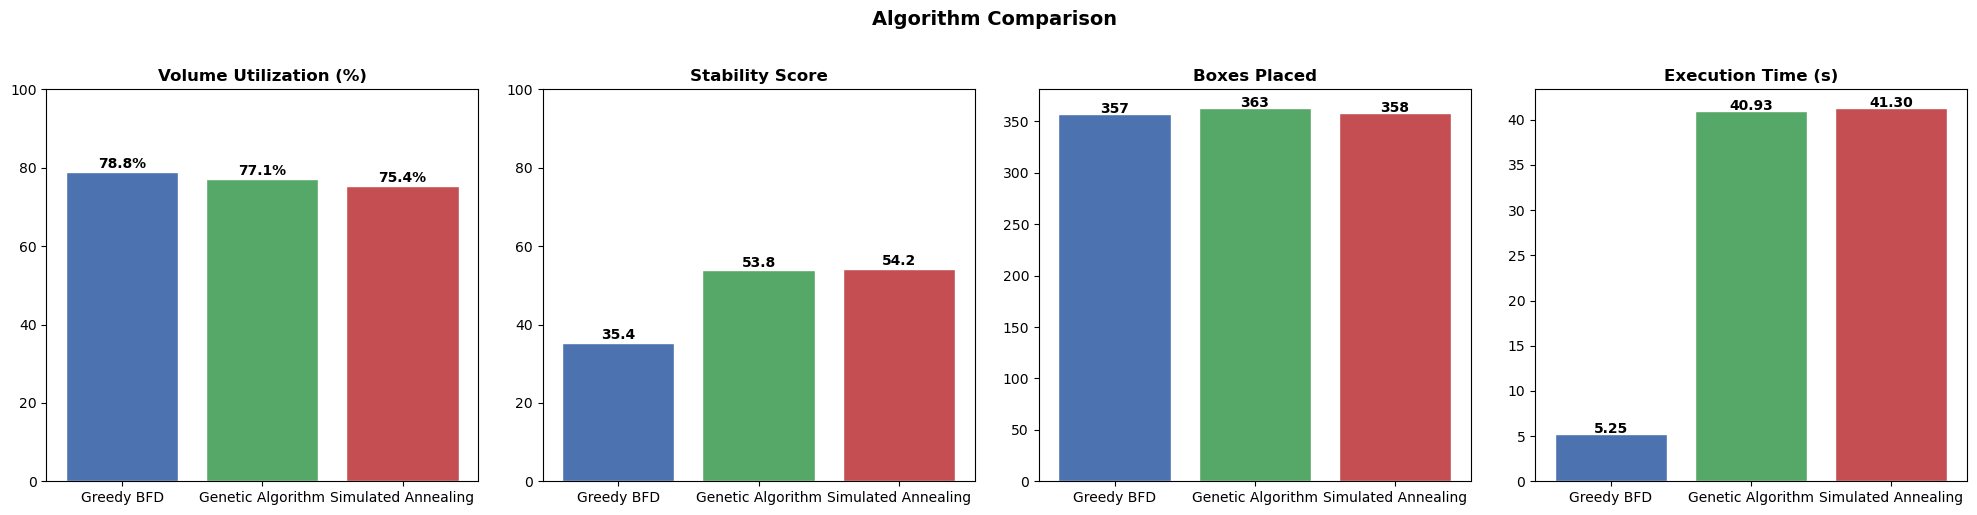

In [36]:
algo_names = list(results.keys())
utils = [results[a]['utilization'] for a in algo_names]
stabs = [results[a]['stability'] for a in algo_names]
times = [results[a]['time'] for a in algo_names]
placed = [results[a]['boxes_placed'] for a in algo_names]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
colors = ['#4C72B0', '#55A868', '#C44E52']

axes[0].bar(algo_names, utils, color=colors, edgecolor='white')
axes[0].set_title('Volume Utilization (%)', fontweight='bold')
axes[0].set_ylim(0, 100)
for i, v in enumerate(utils): axes[0].text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')

axes[1].bar(algo_names, stabs, color=colors, edgecolor='white')
axes[1].set_title('Stability Score', fontweight='bold')
axes[1].set_ylim(0, 100)
for i, v in enumerate(stabs): axes[1].text(i, v + 1, f'{v:.1f}', ha='center', fontweight='bold')

axes[2].bar(algo_names, placed, color=colors, edgecolor='white')
axes[2].set_title('Boxes Placed', fontweight='bold')
for i, v in enumerate(placed): axes[2].text(i, v + 1, str(v), ha='center', fontweight='bold')

axes[3].bar(algo_names, times, color=colors, edgecolor='white')
axes[3].set_title('Execution Time (s)', fontweight='bold')
for i, v in enumerate(times): axes[3].text(i, v + 0.1, f'{v:.2f}', ha='center', fontweight='bold')

plt.suptitle('Algorithm Comparison', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 11. Solution Verification

We verify that every solution satisfies the three physical constraints:
1. **Boundary** — every box fits inside the container
2. **No Overlap** — no two boxes intersect
3. **Gravity** — every box rests on the floor or on another box


In [37]:
def check_boundary(positions, container):
    violations = []
    for p in positions:
        if p['x'] + p['l'] > container.L + 1e-6 or p['y'] + p['w'] > container.W + 1e-6 or p['z'] + p['h'] > container.H + 1e-6:
            violations.append(p['id'])
    return violations

def check_overlap(positions):
    violations = []
    for i in range(len(positions)):
        for j in range(i + 1, len(positions)):
            a, b = positions[i], positions[j]
            if not (a['x'] + a['l'] <= b['x'] + 1e-6 or b['x'] + b['l'] <= a['x'] + 1e-6 or
                    a['y'] + a['w'] <= b['y'] + 1e-6 or b['y'] + b['w'] <= a['y'] + 1e-6 or
                    a['z'] + a['h'] <= b['z'] + 1e-6 or b['z'] + b['h'] <= a['z'] + 1e-6):
                violations.append((a['id'], b['id']))
    return violations

def check_floating(positions):
    violations = []
    for p in positions:
        if abs(p['z']) < 1e-6:
            continue  # on floor
        supported = False
        for other in positions:
            if other is p:
                continue
            if abs((other['z'] + other['h']) - p['z']) < 1e-6:
                if (p['x'] < other['x'] + other['l'] and p['x'] + p['l'] > other['x'] and
                    p['y'] < other['y'] + other['w'] and p['y'] + p['w'] > other['y']):
                    supported = True
                    break
        if not supported:
            violations.append(p['id'])
    return violations

print('Solution Verification')
print('=' * 70)
for name, r in results.items():
    pos = r['positions']
    bv = check_boundary(pos, container)
    ov = check_overlap(pos)
    fv = check_floating(pos)
    status = '✓ PASS' if not (bv or ov or fv) else '✗ FAIL'
    print(f'{name:<25} {status}')
    if bv: print(f'  Boundary violations: {len(bv)}')
    if ov: print(f'  Overlap violations:  {len(ov)}')
    if fv: print(f'  Floating violations: {len(fv)}')
print('=' * 70)


Solution Verification
Greedy BFD                ✓ PASS
Genetic Algorithm         ✓ PASS
Simulated Annealing       ✓ PASS


## 12. 3D Visualization

3D rendering of the packed container for each algorithm, allowing visual comparison of the packing strategies

Rendering: Greedy BFD (78.82%, 357/386 boxes)...


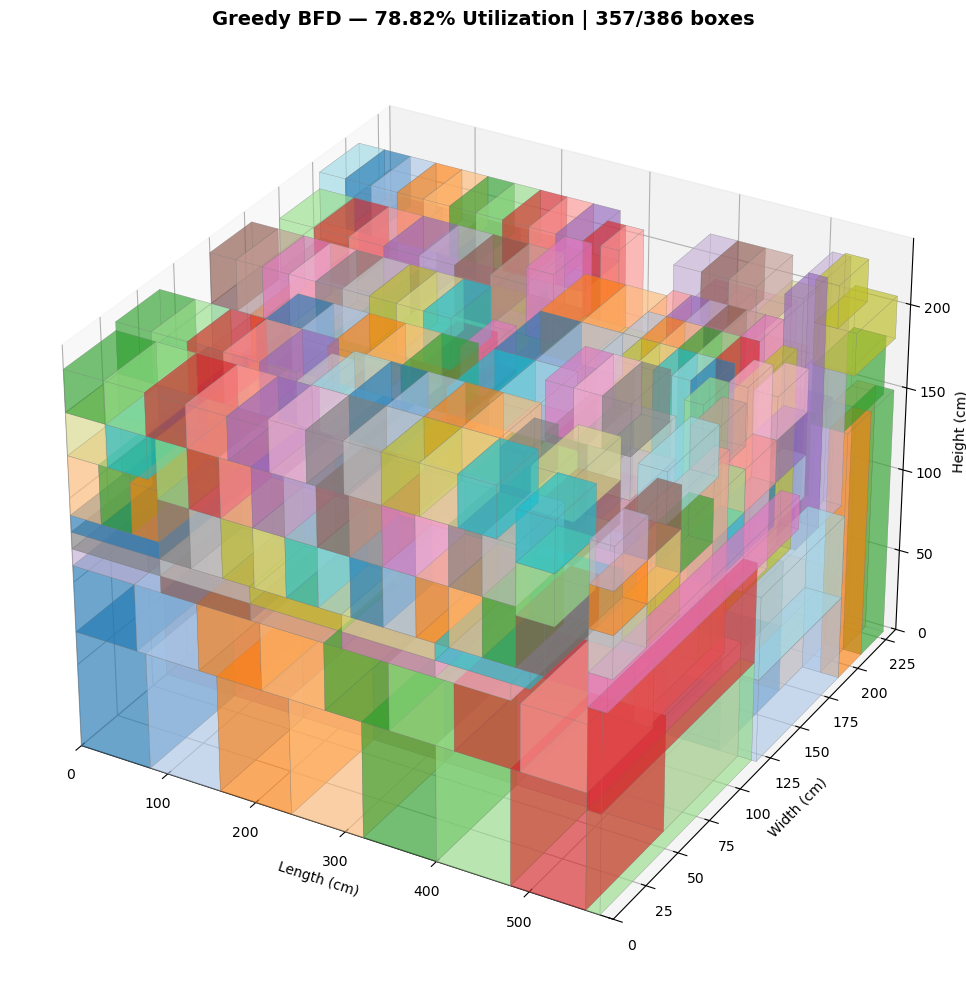

Rendering: Genetic Algorithm (77.13%, 363/386 boxes)...


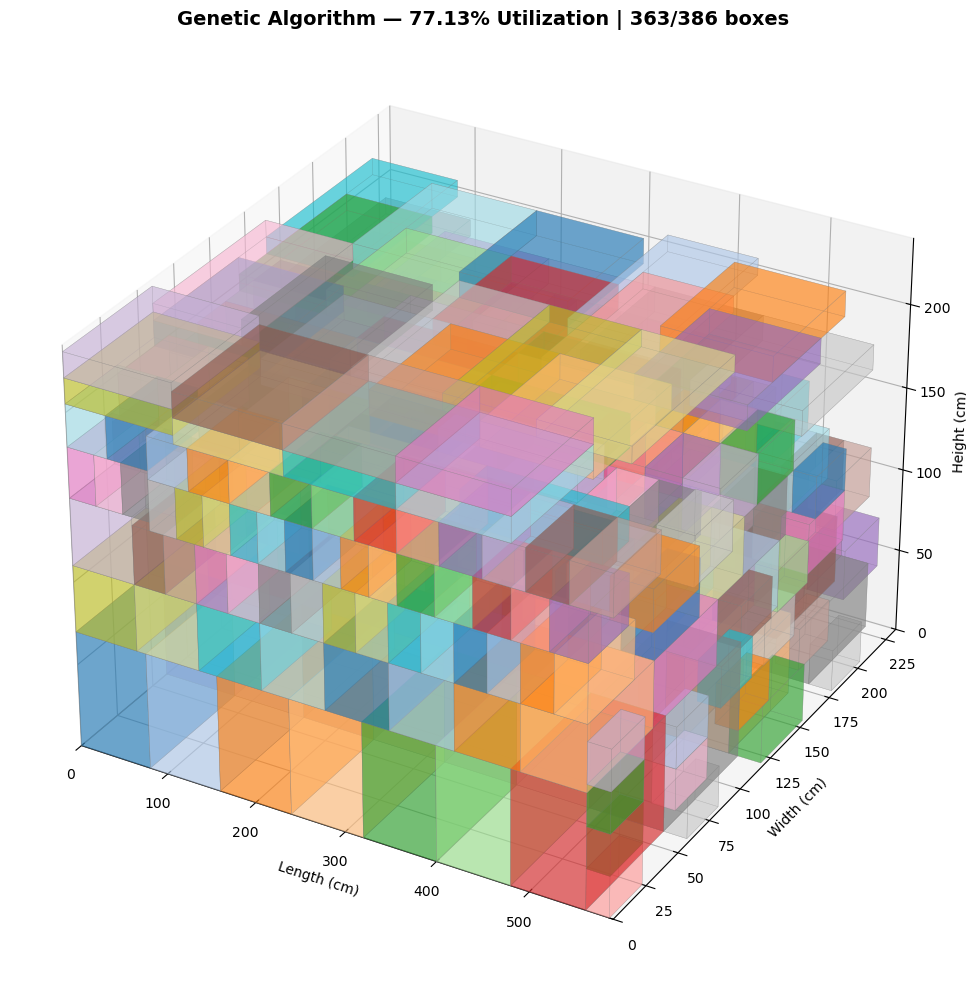

Rendering: Simulated Annealing (75.43%, 358/386 boxes)...


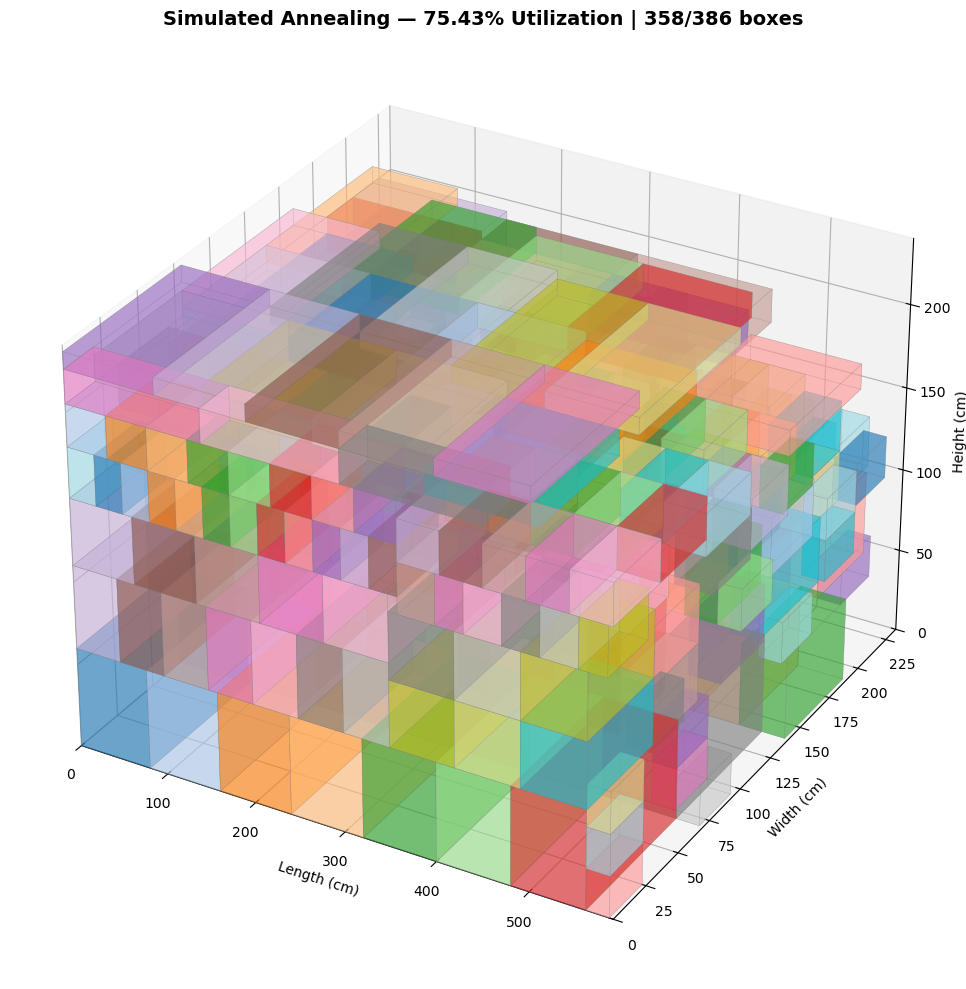

In [39]:
def draw_box_3d(ax, x, y, z, l, w, h, color='skyblue', alpha=0.3):
    vertices = [
        [x,   y,   z],   [x+l, y,   z],   [x+l, y+w, z],   [x,   y+w, z],
        [x,   y,   z+h], [x+l, y,   z+h], [x+l, y+w, z+h], [x,   y+w, z+h],
    ]
    faces = [
        [vertices[j] for j in [0,1,5,4]],
        [vertices[j] for j in [2,3,7,6]],
        [vertices[j] for j in [0,3,7,4]],
        [vertices[j] for j in [1,2,6,5]],
        [vertices[j] for j in [0,1,2,3]],
        [vertices[j] for j in [4,5,6,7]],
    ]
    ax.add_collection3d(Poly3DCollection(faces, alpha=alpha, facecolor=color, edgecolor='gray', linewidth=0.3))


def visualize_solution(positions, container, title='3D Packing'):
    fig = plt.figure(figsize=(14, 10))
    ax = fig.add_subplot(111, projection='3d')
    cmap = plt.cm.tab20
    for i, p in enumerate(positions):
        color = cmap(i % 20)
        draw_box_3d(ax, p['x'], p['y'], p['z'], p['l'], p['w'], p['h'], color=color, alpha=0.4)
    ax.set_xlim(0, container.L)
    ax.set_ylim(0, container.W)
    ax.set_zlim(0, container.H)
    ax.set_xlabel('Length (cm)')
    ax.set_ylabel('Width (cm)')
    ax.set_zlabel('Height (cm)')
    ax.set_title(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Visualize ALL algorithms
for name, r in results.items():
    print(f'Rendering: {name} ({r["utilization"]:.2f}%, {r["boxes_placed"]}/{len(boxes)} boxes)...')
    visualize_solution(
        r['positions'],
        container,
        title=f'{name} — {r["utilization"]:.2f}% Utilization | {r["boxes_placed"]}/{len(boxes)} boxes'
    )

## 13. Conclusion

### Summary of Results

| Algorithm | Utilization | Boxes Placed | Stability | Time |
|---|---|---|---|---|
| Greedy BFD | 78.82% | 357 / 386 | 35.37 | ~5s |
| Genetic Algorithm | 77.13% | 363 / 386 | 53.79 | ~41s |
| Simulated Annealing | 75.43% | 358 / 386 | 54.18 | ~41s |

### Key Observations

1. **Greedy BFD** achieves the highest volume utilization (78.82%) in the shortest 
   time (~5s). Its Extreme Points / BLF placement strategy is highly effective for 
   this dataset, though it sacrifices stability (score: 35.37).

2. **Genetic Algorithm** places the most boxes (363/386) and achieves significantly 
   better stability (53.79) than Greedy, at the cost of longer runtime (~41s). 
   Its population-based search finds orderings that better respect the heavy-at-bottom 
   objective.

3. **Simulated Annealing** achieves the best stability score (54.18) with competitive 
   box placement (358/386), using a calibrated cooling schedule with multi-restart to 
   balance exploration and exploitation.

### Trade-offs

- **Speed vs. Stability**: Greedy is fast and maximizes volume, but GA and SA 
  invest more time to achieve significantly better stability scores (~54 vs ~35).
- **Utilization vs. Boxes Placed**: Greedy has higher utilization % but places 
  fewer boxes (357) than GA (363), because GA finds more compact rotations.
- **Determinism vs. Stochasticity**: Greedy always produces the same result; 
  GA and SA are seed-dependent but consistently improve stability.
